# Hardware Performance Comparison Report

## 1. Objective

This notebook consolidates and analyzes inference benchmarking results
for a PyTorch-based Human Activity Recognition (HAR) CNN across three
hardware platforms:

- CPU (Local machine)
- NVIDIA Tesla T4 GPU (Google Colab)
- Google TPU v5e (Google Colab)

The objective is to compare inference latency, batch processing time,
throughput, and run-to-run variability under a consistent benchmark
protocol.

## 2. Benchmark Configuration

- Dataset: UCI Human Activity Recognition
- Test samples: 2,947
- Model: HAR_CNN
- Input shape: 6 channels × 128 time steps
- Batch size: 64
- Warm-up: One complete test dataset pass
- Measured runs: 3
- Execution mode: PyTorch inference mode

## Import libraries and load benchmark results

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Project paths
PROJECT_ROOT = Path.cwd().parent
RESULTS_DIR = PROJECT_ROOT / "results"

# Benchmark result files
cpu_file = RESULTS_DIR / "inference_benchmark_cpu_standardized.csv"
gpu_file = RESULTS_DIR / "inference_benchmark_gpu_standardized.csv"
tpu_file = RESULTS_DIR / "inference_benchmark_tpu_standardized.csv"

# Check that all files exist
for file in [cpu_file, gpu_file, tpu_file]:
    print(file.name, ":", file.exists())

# Load results
cpu_df = pd.read_csv(cpu_file)
gpu_df = pd.read_csv(gpu_file)
tpu_df = pd.read_csv(tpu_file)

print("\nAll benchmark files loaded successfully.")

inference_benchmark_cpu_standardized.csv : True
inference_benchmark_gpu_standardized.csv : True
inference_benchmark_tpu_standardized.csv : True

All benchmark files loaded successfully.


## Combine the results

In [2]:
# Combine all hardware results
comparison_df = pd.concat(
    [cpu_df, gpu_df, tpu_df],
    ignore_index=True
)

# Select relevant columns
comparison_df = comparison_df[
    [
        "device",
        "hardware",
        "average_time_seconds",
        "median_time_seconds",
        "std_time_seconds",
        "average_batch_time_ms",
        "throughput_samples_per_second",
        "test_samples",
        "batch_size",
        "warmup_passes",
        "benchmark_runs"
    ]
]

display(comparison_df)

,device,hardware,average_time_seconds,median_time_seconds,std_time_seconds,average_batch_time_ms,throughput_samples_per_second,test_samples,batch_size,warmup_passes,benchmark_runs
0,CPU,Local CPU,0.096353,0.097061,0.001801,2.050070,30585.356180,2947,64,1,3
1,GPU,Tesla T4,0.049338,0.046847,0.005487,1.049743,59730.933124,2947,64,1,3
2,TPU,Google TPU v5e,0.078957,0.078872,0.001391,1.679944,37323.944209,2947,64,1,3


## Validate experimental consistency

In [3]:
# Verify that all benchmarks used the same configuration
assert comparison_df["test_samples"].nunique() == 1
assert comparison_df["batch_size"].nunique() == 1
assert comparison_df["warmup_passes"].nunique() == 1
assert comparison_df["benchmark_runs"].nunique() == 1

assert len(comparison_df) == 3

print("Benchmark validation successful!")
print("Test samples:", comparison_df["test_samples"].iloc[0])
print("Batch size:", comparison_df["batch_size"].iloc[0])
print("Warm-up passes:", comparison_df["warmup_passes"].iloc[0])
print("Measured runs:", comparison_df["benchmark_runs"].iloc[0])

Benchmark validation successful!
Test samples: 2947
Batch size: 64
Warm-up passes: 1
Measured runs: 3


## 3. Relative Performance Analysis

The local CPU is used as the baseline hardware.

Speedup is calculated as the CPU throughput divided by the
throughput of the other hardware platform.

A speedup greater than 1 indicates higher throughput than the CPU.

In [4]:
# Get CPU throughput as baseline
cpu_throughput = comparison_df.loc[
    comparison_df["device"] == "CPU",
    "throughput_samples_per_second"
].iloc[0]

# Calculate speedup relative to CPU
comparison_df["speedup_vs_cpu"] = (
    comparison_df["throughput_samples_per_second"] / cpu_throughput
)

# Calculate throughput improvement percentage
comparison_df["throughput_improvement_percent"] = (
    (comparison_df["speedup_vs_cpu"] - 1) * 100
)

display(
    comparison_df[
        [
            "device",
            "hardware",
            "throughput_samples_per_second",
            "speedup_vs_cpu",
            "throughput_improvement_percent"
        ]
    ].round(3)
)

,device,hardware,throughput_samples_per_second,speedup_vs_cpu,throughput_improvement_percent
0,CPU,Local CPU,30585.356,1.000,0.000
1,GPU,Tesla T4,59730.933,1.953,95.293
2,TPU,Google TPU v5e,37323.944,1.220,22.032


## 4. Hardware Performance Visualization

### 4.1 Inference Throughput

This chart compares the number of test samples processed per second
by each hardware platform. Higher throughput indicates better
inference performance.

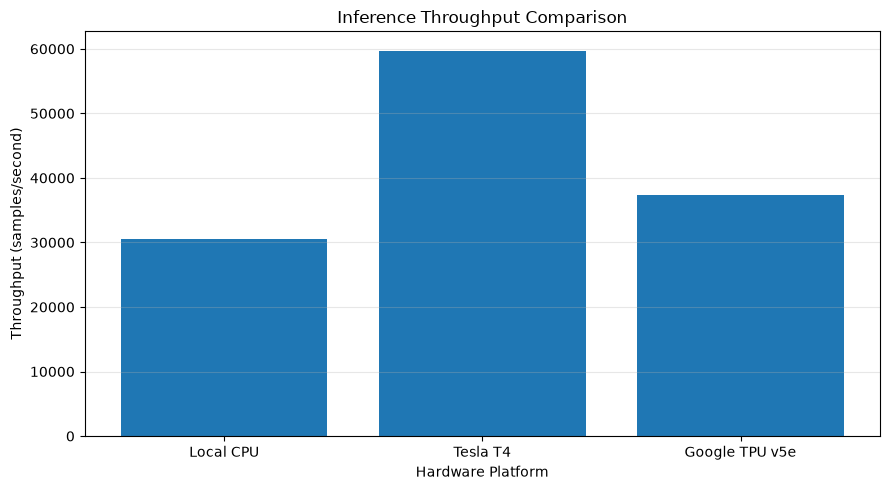

In [5]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["hardware"],
    comparison_df["throughput_samples_per_second"]
)

plt.title("Inference Throughput Comparison")
plt.xlabel("Hardware Platform")
plt.ylabel("Throughput (samples/second)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 4.2 Average Inference Time

This chart compares the total time required to process all 2,947
test samples. Lower inference time indicates better performance.

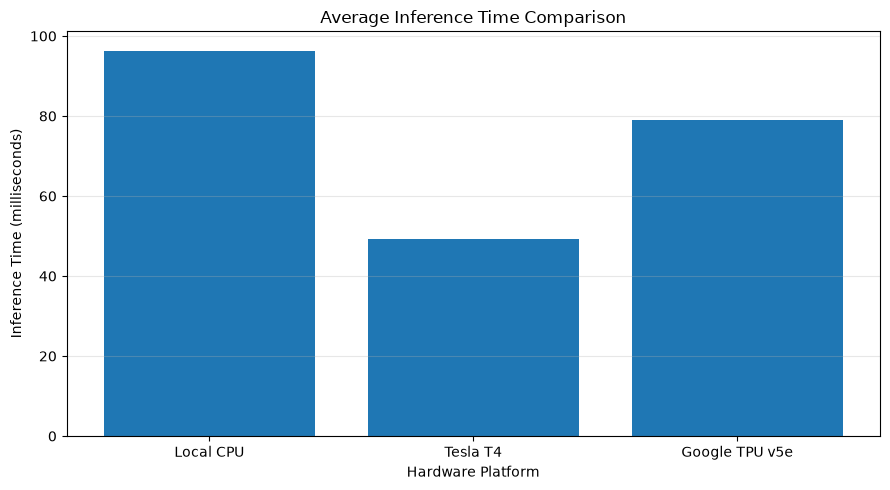

In [6]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["hardware"],
    comparison_df["average_time_seconds"] * 1000
)

plt.title("Average Inference Time Comparison")
plt.xlabel("Hardware Platform")
plt.ylabel("Inference Time (milliseconds)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 4.3 Run-to-Run Variability

This comparison uses the standard deviation of the three measured
inference runs.

A lower standard deviation indicates more consistent execution
times across the measured runs.

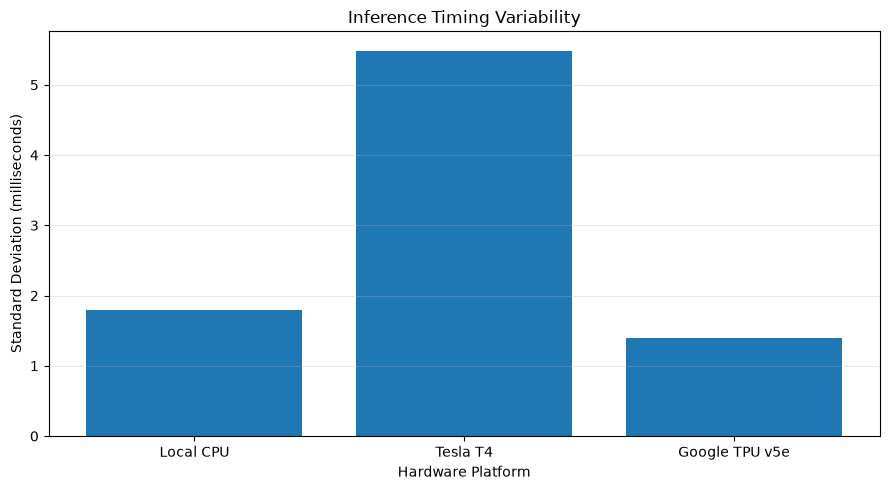

In [7]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["hardware"],
    comparison_df["std_time_seconds"] * 1000
)

plt.title("Inference Timing Variability")
plt.xlabel("Hardware Platform")
plt.ylabel("Standard Deviation (milliseconds)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Consolidated Benchmark Results

The benchmark results from all three hardware platforms are
combined into a single CSV file for reproducibility and further analysis.

In [8]:
# Save consolidated results
comparison_file = RESULTS_DIR / "hardware_comparison.csv"

comparison_df.to_csv(
    comparison_file,
    index=False
)

print("Comparison results saved to:", comparison_file)

display(comparison_df.round(4))

Comparison results saved to: d:\sensor-har-pytorch-accelerators\results\hardware_comparison.csv


,device,hardware,average_time_seconds,median_time_seconds,std_time_seconds,average_batch_time_ms,throughput_samples_per_second,test_samples,batch_size,warmup_passes,benchmark_runs,speedup_vs_cpu,throughput_improvement_percent
0,CPU,Local CPU,0.0964,0.0971,0.0018,2.0501,30585.3562,2947,64,1,3,1.0000,0.0000
1,GPU,Tesla T4,0.0493,0.0468,0.0055,1.0497,59730.9331,2947,64,1,3,1.9529,95.2926
2,TPU,Google TPU v5e,0.0790,0.0789,0.0014,1.6799,37323.9442,2947,64,1,3,1.2203,22.0321


In [9]:
import matplotlib.pyplot as plt


# Consistent hardware colors
hardware_colors = {
    "CPU": "#4C78A8",
    "GPU": "#22A06B",
    "TPU": "#9467BD"
}

# Prepare data
df = comparison_df.copy()

df["average_time_ms"] = df["average_time_seconds"] * 1000
df["std_time_ms"] = df["std_time_seconds"] * 1000

# Consistent plotting order
df["device"] = pd.Categorical(
    df["device"],
    categories=["CPU", "GPU", "TPU"],
    ordered=True
)

df = df.sort_values("device")

colors = [
    hardware_colors[device]
    for device in df["device"]
]

# Shared visual styling
plt.rcParams.update({
    "figure.figsize": (11, 6),
    "figure.dpi": 120,
    "font.family": "DejaVu Sans",
    "axes.titleweight": "bold",
    "axes.titlesize": 17,
    "axes.labelsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 10
})


## Chart 1 — Throughput

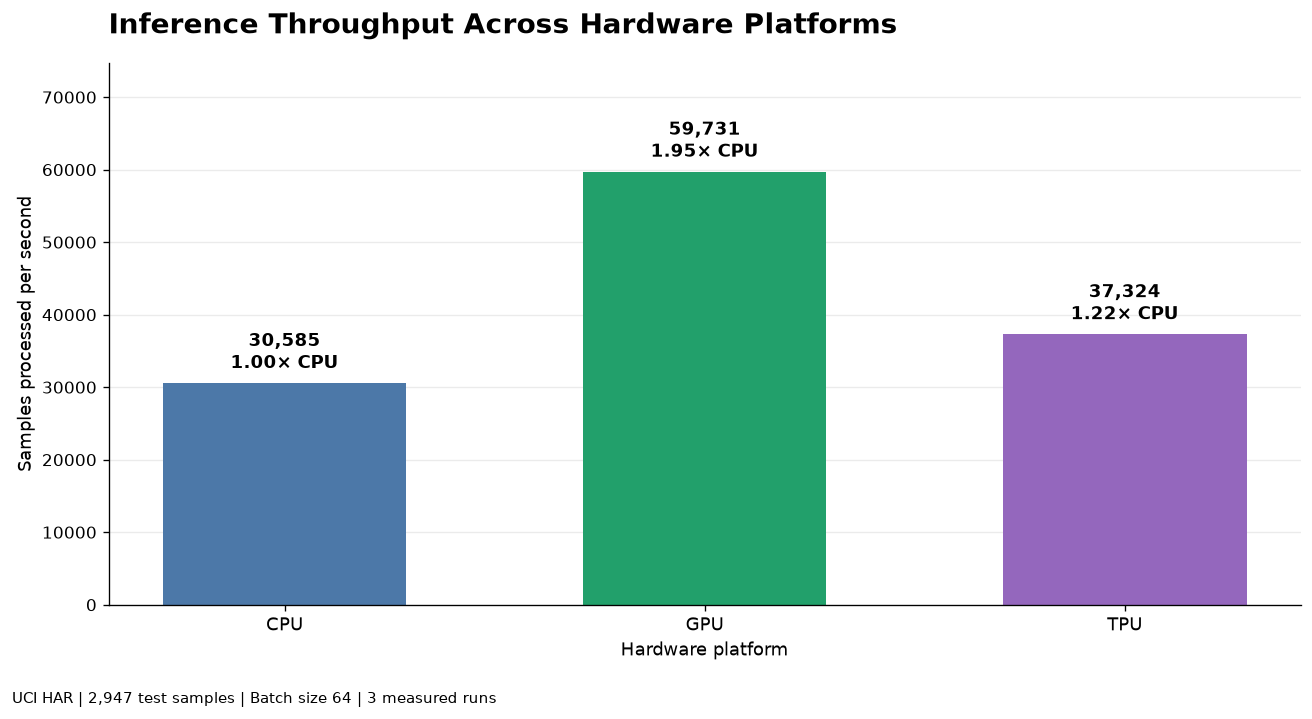

In [11]:
fig, ax = plt.subplots()

bars = ax.bar(
    df["device"].astype(str),
    df["throughput_samples_per_second"],
    color=colors,
    width=0.58
)

cpu_value = df.loc[
    df["device"] == "CPU",
    "throughput_samples_per_second"
].iloc[0]

for bar, value in zip(
    bars,
    df["throughput_samples_per_second"]
):
    speedup = value / cpu_value

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1200,
        f"{value:,.0f}\n{speedup:.2f}× CPU",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Inference Throughput Across Hardware Platforms",
    loc="left",
    pad=18
)

ax.set_ylabel("Samples processed per second")
ax.set_xlabel("Hardware platform")

ax.text(
    0.99, 0.96,
    "",
    transform=ax.transAxes,
    ha="right",
    color="#23865A",
    fontweight="bold"
)

ax.set_ylim(0, df["throughput_samples_per_second"].max() * 1.25)

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

fig.text(
    0.01, 0.015,
    "UCI HAR | 2,947 test samples | Batch size 64 | 3 measured runs",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(
    RESULTS_DIR / "throughput_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## Chart 2 — Average inference time with error bars

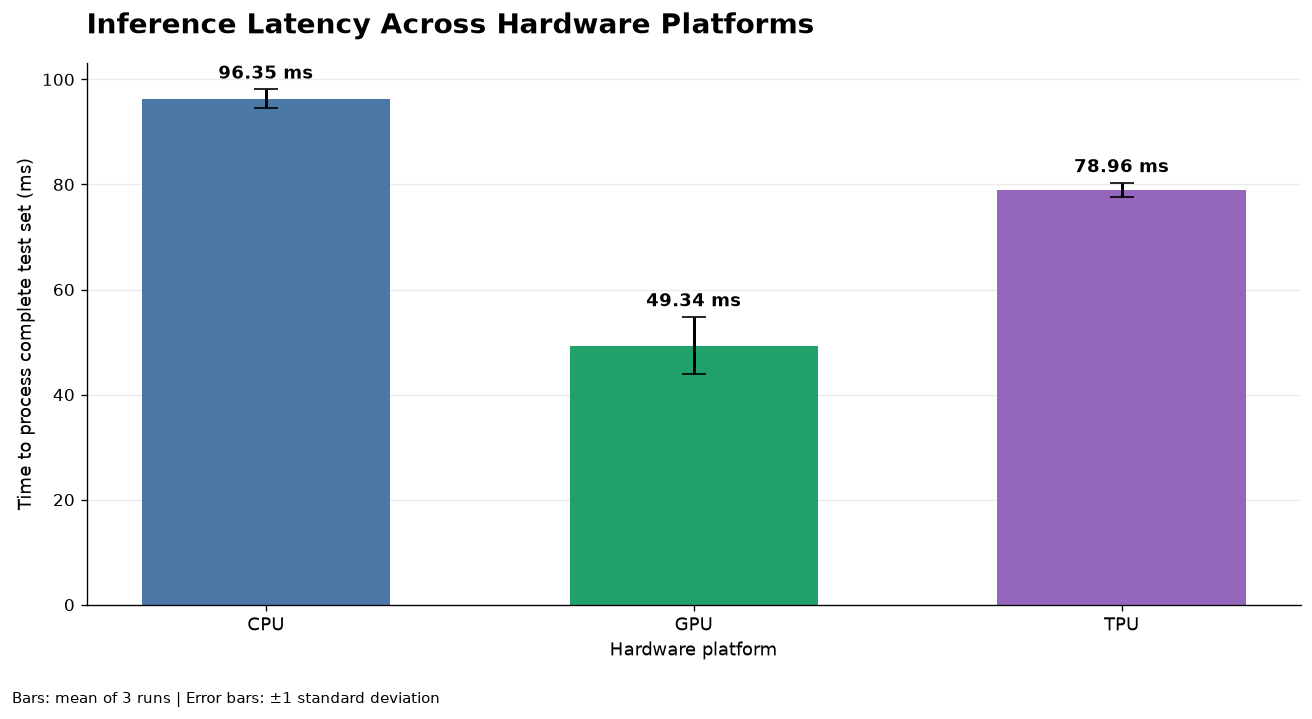

In [16]:
fig, ax = plt.subplots()

bars = ax.bar(
    df["device"].astype(str),
    df["average_time_ms"],
    yerr=df["std_time_ms"],
    capsize=7,
    color=colors,
    width=0.58,
    error_kw={"elinewidth": 1.8}
)

for bar, value, std in zip(
    bars,
    df["average_time_ms"],
    df["std_time_ms"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + std + 2,
        f"{value:.2f} ms",
        ha="center",
        fontweight="bold",
        fontsize=11
    )

ax.set_title(
    "Inference Latency Across Hardware Platforms",
    loc="left",
    pad=18
)

ax.set_ylabel("Time to process complete test set (ms)")
ax.set_xlabel("Hardware platform")

ax.text(
    0.99, 0.96,
    "",
    transform=ax.transAxes,
    ha="right",
    color="#A15D35",
    fontweight="bold"
)

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

fig.text(
    0.01, 0.015,
    "Bars: mean of 3 runs | Error bars: ±1 standard deviation",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(
    RESULTS_DIR / "inference_latency_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## Run-to-run variability

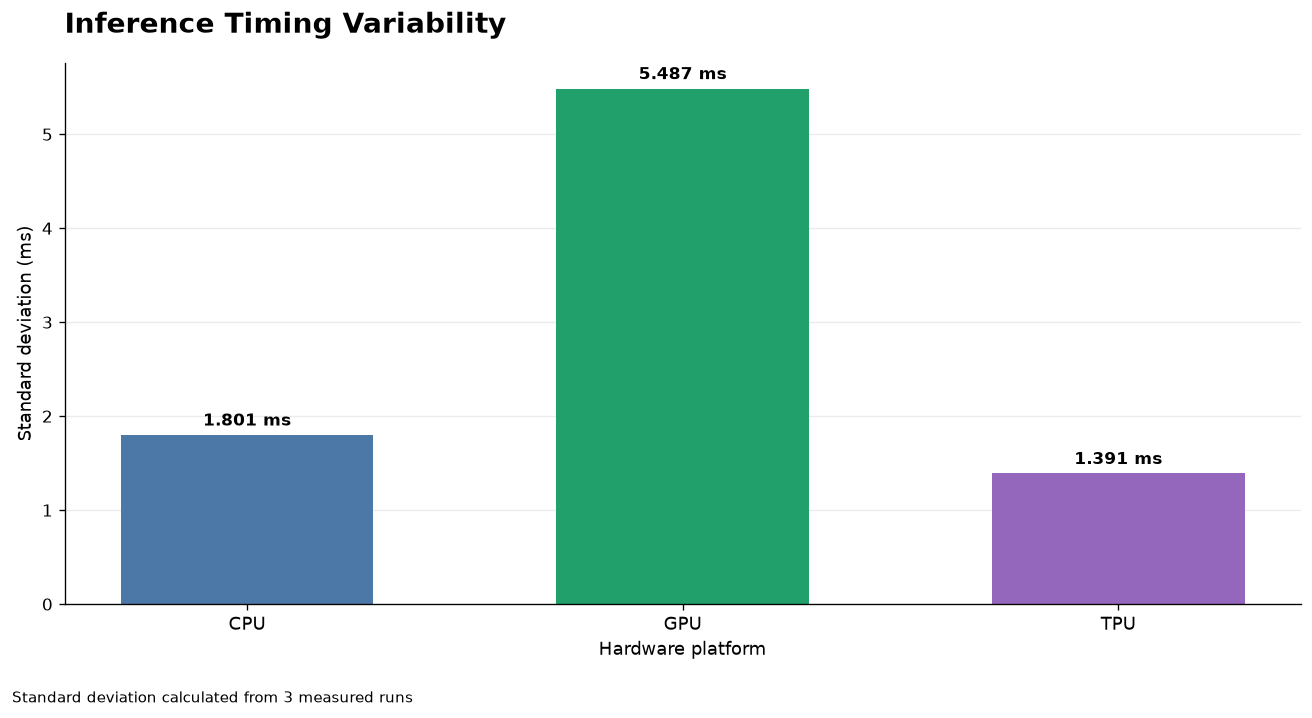

In [15]:
fig, ax = plt.subplots()

bars = ax.bar(
    df["device"].astype(str),
    df["std_time_ms"],
    color=colors,
    width=0.58
)

for bar, value in zip(bars, df["std_time_ms"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{value:.3f} ms",
        ha="center",
        fontweight="bold"
    )

ax.set_title(
    "Inference Timing Variability",
    loc="left",
    pad=18
)

ax.set_ylabel("Standard deviation (ms)")
ax.set_xlabel("Hardware platform")

ax.text(
    0.99, 0.96,
    "",
    transform=ax.transAxes,
    ha="right",
    fontsize=9,
    fontweight="bold"
)

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

fig.text(
    0.01, 0.015,
    "Standard deviation calculated from 3 measured runs",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(
    RESULTS_DIR / "timing_variability_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## Dataset & experiment infographic

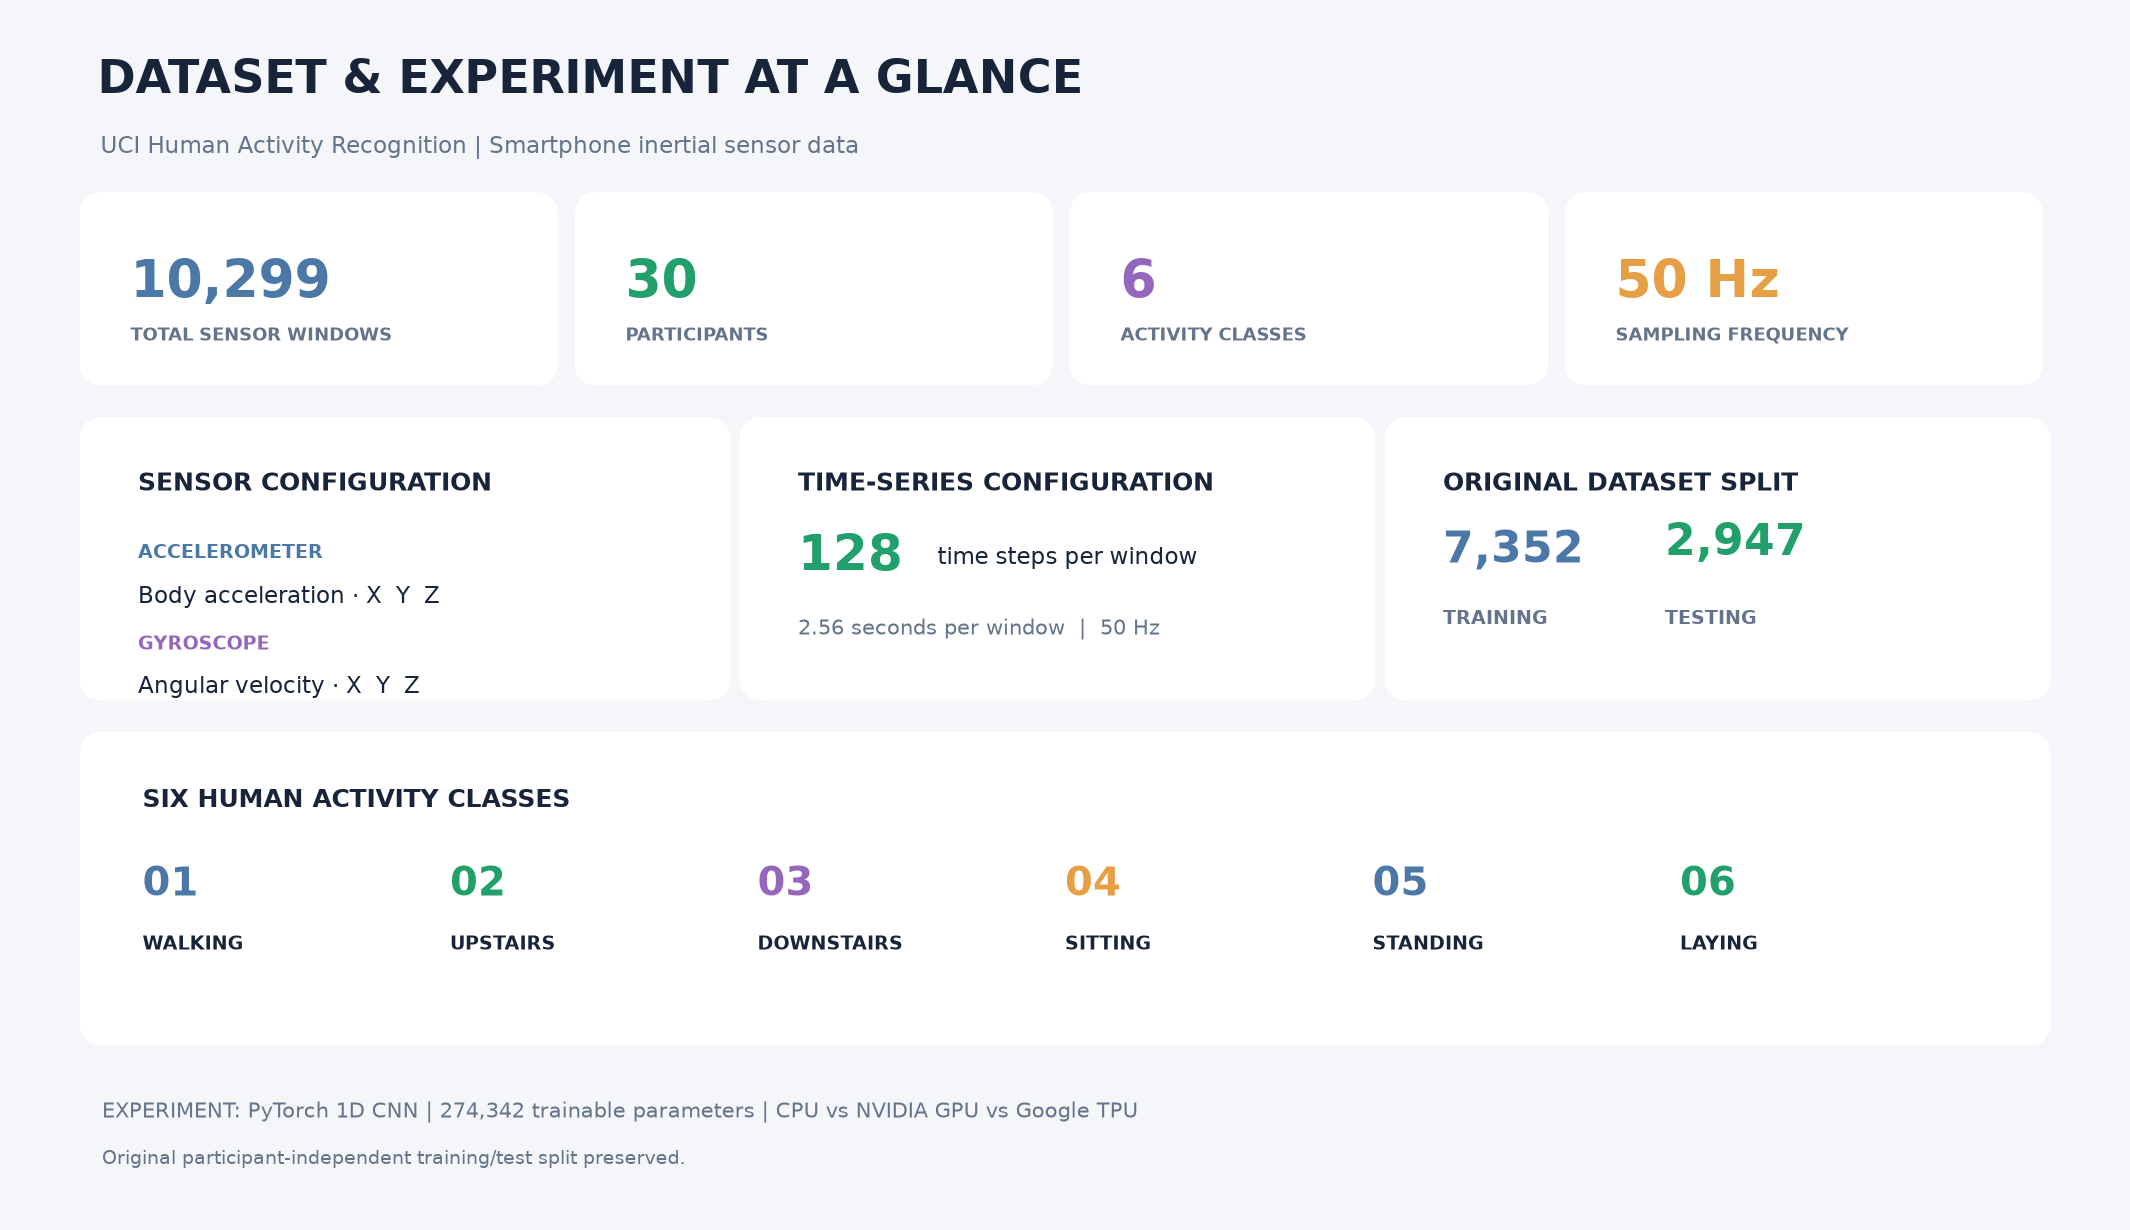

In [17]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# --------------------------------------------------
# 1. Figure setup
# --------------------------------------------------

fig = plt.figure(figsize=(14, 8), dpi=150)
fig.patch.set_facecolor("#F4F6FA")

ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, 14)
ax.set_ylim(0, 8)
ax.axis("off")

# Color palette
NAVY = "#17243A"
BLUE = "#4C78A8"
GREEN = "#22A06B"
PURPLE = "#9467BD"
ORANGE = "#E69F45"
MUTED = "#64748B"
WHITE = "#FFFFFF"
LIGHT = "#E9EEF5"


# --------------------------------------------------
# 2. Helper function for information cards
# --------------------------------------------------

def add_card(x, y, width, height, color=WHITE):
    card = FancyBboxPatch(
        (x, y),
        width,
        height,
        boxstyle="round,pad=0.12,rounding_size=0.16",
        facecolor=color,
        edgecolor="none"
    )
    ax.add_patch(card)


# --------------------------------------------------
# 3. Header
# --------------------------------------------------

ax.text(
    0.55, 7.48,
    "DATASET & EXPERIMENT AT A GLANCE",
    fontsize=22,
    fontweight="bold",
    color=NAVY
)

ax.text(
    0.57, 7.08,
    "UCI Human Activity Recognition | Smartphone inertial sensor data",
    fontsize=11,
    color=MUTED
)


# --------------------------------------------------
# 4. Main dataset metrics
# --------------------------------------------------

metrics = [
    ("10,299", "TOTAL SENSOR WINDOWS", BLUE),
    ("30", "PARTICIPANTS", GREEN),
    ("6", "ACTIVITY CLASSES", PURPLE),
    ("50 Hz", "SAMPLING FREQUENCY", ORANGE)
]

x_positions = [0.55, 3.85, 7.15, 10.45]

for (value, label, color), x in zip(metrics, x_positions):
    add_card(x, 5.65, 2.95, 1.05)

    ax.text(
        x + 0.22, 6.12,
        value,
        fontsize=25,
        fontweight="bold",
        color=color
    )

    ax.text(
        x + 0.22, 5.83,
        label,
        fontsize=8.5,
        fontweight="bold",
        color=MUTED
    )


# --------------------------------------------------
# 5. Sensor configuration
# --------------------------------------------------

add_card(0.55, 3.55, 4.1, 1.65)

ax.text(
    0.82, 4.83,
    "SENSOR CONFIGURATION",
    fontsize=12,
    fontweight="bold",
    color=NAVY
)

ax.text(
    0.82, 4.38,
    "ACCELEROMETER",
    fontsize=9,
    fontweight="bold",
    color=BLUE
)

ax.text(
    0.82, 4.08,
    "Body acceleration · X  Y  Z",
    fontsize=11,
    color=NAVY
)

ax.text(
    0.82, 3.77,
    "GYROSCOPE",
    fontsize=9,
    fontweight="bold",
    color=PURPLE
)

ax.text(
    0.82, 3.48,
    "Angular velocity · X  Y  Z",
    fontsize=11,
    color=NAVY
)


# --------------------------------------------------
# 6. Time-series configuration
# --------------------------------------------------

add_card(4.95, 3.55, 4.0, 1.65)

ax.text(
    5.22, 4.83,
    "TIME-SERIES CONFIGURATION",
    fontsize=12,
    fontweight="bold",
    color=NAVY
)

ax.text(
    5.22, 4.30,
    "128",
    fontsize=24,
    fontweight="bold",
    color=GREEN
)

ax.text(
    6.15, 4.34,
    "time steps per window",
    fontsize=11,
    color=NAVY
)

ax.text(
    5.22, 3.87,
    "2.56 seconds per window  |  50 Hz",
    fontsize=10,
    color=MUTED
)


# --------------------------------------------------
# 7. Dataset split
# --------------------------------------------------

add_card(9.25, 3.55, 4.2, 1.65)

ax.text(
    9.52, 4.83,
    "ORIGINAL DATASET SPLIT",
    fontsize=12,
    fontweight="bold",
    color=NAVY
)

ax.text(
    9.52, 4.35,
    "7,352",
    fontsize=21,
    fontweight="bold",
    color=BLUE
)

ax.text(
    11.0, 4.40,
    "2,947",
    fontsize=21,
    fontweight="bold",
    color=GREEN
)

ax.text(
    9.52, 3.94,
    "TRAINING",
    fontsize=9,
    fontweight="bold",
    color=MUTED
)

ax.text(
    11.0, 3.94,
    "TESTING",
    fontsize=9,
    fontweight="bold",
    color=MUTED
)


# --------------------------------------------------
# 8. Activity classes
# --------------------------------------------------

add_card(0.55, 1.25, 12.9, 1.85)

ax.text(
    0.85, 2.72,
    "SIX HUMAN ACTIVITY CLASSES",
    fontsize=12,
    fontweight="bold",
    color=NAVY
)

activities = [
    ("01", "WALKING", BLUE),
    ("02", "UPSTAIRS", GREEN),
    ("03", "DOWNSTAIRS", PURPLE),
    ("04", "SITTING", ORANGE),
    ("05", "STANDING", BLUE),
    ("06", "LAYING", GREEN)
]

for i, (number, activity, color) in enumerate(activities):
    x = 0.85 + i * 2.05

    ax.text(
        x, 2.13,
        number,
        fontsize=19,
        fontweight="bold",
        color=color
    )

    ax.text(
        x, 1.77,
        activity,
        fontsize=9,
        fontweight="bold",
        color=NAVY
    )


# --------------------------------------------------
# 9. Footer
# --------------------------------------------------

ax.text(
    0.58, 0.65,
    "EXPERIMENT: PyTorch 1D CNN | 274,342 trainable parameters | "
    "CPU vs NVIDIA GPU vs Google TPU",
    fontsize=10,
    color=MUTED
)

ax.text(
    0.58, 0.34,
    "Original participant-independent training/test split preserved.",
    fontsize=9,
    color=MUTED
)


# --------------------------------------------------
# 10. Export
# --------------------------------------------------

plt.savefig(
    RESULTS_DIR / "dataset_experiment_overview.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()
